# 🎯 02 · 抽样分布与中心极限定理（CLT）

> 上一课学了分布，这一课回答：**为什么样本均值能代表总体？**
> 核心是三件事：抽样分布、标准误（SE）、中心极限定理（CLT）。
> CLT 是假设检验与置信区间的数学地基。

## 📋 本节要解决的问题

- 样本均值本身的分布长什么样？标准误 = σ/√n 怎么来的？
- 为什么"原始分布不是正态"时，样本均值仍是正态（CLT）？
- n 要多大 CLT 才近似成立？哪些分布收敛慢？
- 标准误（SE）与标准差（SD）到底什么区别？

## 📖 论文配图：SOCR 中心极限定理模拟器

> **图源**：Dinov ID, Christou N & Sanchez J (2008) *Central Limit Theorem: New SOCR Applet and Demonstration Activity*, Journal of Statistics Education 16(1)（开放获取，教育用途）图 1。

![SOCR 中心极限定理模拟器](../figures/socr_clt_applet.jpg)

> **怎么读这张图**：SOCR（Statistics Online Computational Resource）的教学 Applet 界面：左边选总体分布（均匀/指数/二项/自定义），右边实时展示抽样后样本均值的分布。拖动样本量滑块即可"亲眼"看到样本均值分布随 n 增大逼近正态——这正是本节 CLT 模拟代码的教学原型。


## 1️⃣ 标准误与抽样分布

**抽样分布**：从总体反复抽样、每次算样本均值，这些均值的分布。
- $E(\bar X) = \mu$（无偏）
- $SE(\bar X) = \frac{\sigma}{\sqrt n}$（标准误）

**面试必答**：SD 描述**单个观测**的分散程度；SE 描述**样本均值**的精度。
SE 随 n 增大而变小（√n 关系），这就是"样本越大估计越准"。

In [1]:
import numpy as np
# 从一个偏斜总体反复抽样，看样本均值的分布
rng = np.random.RandomState(5)
pop = rng.exponential(scale=3, size=100000)  # 右偏总体，μ=3, σ=3
print('总体均值=%.3f 总体标准差=%.3f（右偏分布）' % (pop.mean(), pop.std()))

# 抽 5000 次样本，每次 n=30
n, trials = 30, 5000
means = np.array([rng.choice(pop, n, replace=True).mean() for _ in range(trials)])
se_empirical = means.std()
se_theory = pop.std() / np.sqrt(n)
print('样本均值分布: 均值=%.3f 标准误(经验)=%.3f 标准误(理论σ/√n)=%.3f' % (
    means.mean(), se_empirical, se_theory))
print('→ 经验 SE 与理论 SE 高度一致 ✅')
assert abs(se_empirical - se_theory) / se_theory < 0.1, 'SE 应接近 σ/√n'

总体均值=3.009 总体标准差=3.002（右偏分布）
样本均值分布: 均值=3.002 标准误(经验)=0.546 标准误(理论σ/√n)=0.548
→ 经验 SE 与理论 SE 高度一致 ✅


## 2️⃣ CLT 模拟：三种非正态总体的样本均值都趋正态

**中心极限定理**：独立同分布随机变量 $X_1,...,X_n$，当 n 充分大时，
$\bar X$ 近似服从 $N(\mu, \sigma^2/n)$，**与总体分布无关**。

模拟三种"非正态"总体：均匀、指数、伯努利(0/1)，验证它们的样本均值都变成钟形。

C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\backends\backend_agg.py:238: RuntimeWarning: Glyph 178 missing from current font.
  font.set_text(s, 0.0, flags=flags)


C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\backends\backend_agg.py:201: RuntimeWarning: Glyph 178 missing from current font.
  font.set_text(s, 0, flags=flags)


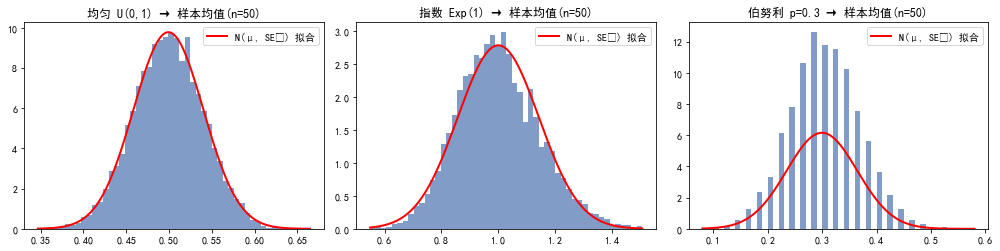

三种非正态总体的样本均值分布都逼近正态 → CLT ✅


In [2]:
import matplotlib.pyplot as plt
from scipy import stats as st
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

rng = np.random.RandomState(11)
n = 50
trials = 8000
pops = [
    ('均匀 U(0,1)', rng.uniform, dict(low=0, high=1)),
    ('指数 Exp(1)', rng.exponential, dict(scale=1)),
    ('伯努利 p=0.3', rng.binomial, dict(n=1, p=0.3)),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (name, fn, kw) in zip(axes, pops):
    samples = np.array([fn(size=n, **kw).mean() for _ in range(trials)])
    ax.hist(samples, bins=50, density=True, alpha=.7, color='#4C72B0')
    xs = np.linspace(samples.min(), samples.max(), 200)
    mu, se = samples.mean(), samples.std()
    ax.plot(xs, st.norm.pdf(xs, mu, se), 'r-', lw=2, label='N(μ, SE²) 拟合')
    ax.set_title('%s → 样本均值(n=%d)' % (name, n))
    ax.legend()
plt.tight_layout()
plt.show()
print('三种非正态总体的样本均值分布都逼近正态 → CLT ✅')

## 3️⃣ n 要多大？（收敛速度对比）

CLT 是渐近结论：n 越大越好。但"多大算够"取决于总体偏斜程度：
- 对称总体（均匀）：n≈15 就很好
- 轻度偏斜：n≈30（经验法则）
- 重尾/极度偏斜（如对数正态）：可能需要 n≥50 甚至上百

> **面试问**：为什么常说 n≥30？→ 对多数分布是够用的经验阈值，
> 但重尾分布要更大样本。判断标准不是 n 本身，而是"样本均值分布的对称性"。

In [3]:
rng = np.random.RandomState(3)
pop = rng.lognormal(0, 1.2, 100000)  # 重尾：对数正态
print('对数正态总体: 均值=%.2f 标准差=%.2f 偏度=%.2f' % (pop.mean(), pop.std(), st.skew(pop)))
for n in [5, 20, 50, 200]:
    means = np.array([rng.choice(pop, n).mean() for _ in range(4000)])
    print('n=%3d → 样本均值偏度=%.3f（越接近 0 越正态）' % (n, st.skew(means)))
print()
print('结论：重尾分布需要更大的 n 才能让样本均值分布接近正态')

对数正态总体: 均值=2.05 标准差=3.75 偏度=11.51
n=  5 → 样本均值偏度=6.068（越接近 0 越正态）
n= 20 → 样本均值偏度=2.664（越接近 0 越正态）


n= 50 → 样本均值偏度=1.561（越接近 0 越正态）
n=200 → 样本均值偏度=0.825（越接近 0 越正态）

结论：重尾分布需要更大的 n 才能让样本均值分布接近正态


## 4️⃣ 标准误 vs 标准差（高频面试）

| | 标准差 SD | 标准误 SE |
|---|---|---|
| 描述对象 | 单个观测 | 样本均值 |
| 公式 | σ（总体）或 s（样本） | σ/√n |
| 随 n 变化 | 不变 | 变小 |
| 用途 | 数据离散程度 | 估计精度/置信区间 |

**面试标准答案**：「SD 衡量数据本身的波动，SE 衡量估计量的波动；
SE = SD/√n，样本量翻 4 倍，SE 减半。」

In [4]:
n_vals = [10, 40, 160, 640]
sd = 4.0
print('固定 σ=4：')
for n in n_vals:
    print('  n=%-4d SE=%.3f   (SD=%.1f 不变)' % (n, sd/np.sqrt(n), sd))
print()
print('→ SE 与 √n 成反比：n×4 → SE÷2')

固定 σ=4：
  n=10   SE=1.265   (SD=4.0 不变)
  n=40   SE=0.632   (SD=4.0 不变)
  n=160  SE=0.316   (SD=4.0 不变)
  n=640  SE=0.158   (SD=4.0 不变)

→ SE 与 √n 成反比：n×4 → SE÷2


## 5️⃣ 应用：用 CLT 做概率题

> 某产品重量 X~N(500, 15²)，抽查 n=25 件，问均值 <495 的概率？
> 解：$\bar X \sim N(500, 15^2/25)$，$P(\bar X<495) = P(Z < \frac{495-500}{15/5}) = P(Z<-1.667)$。

In [5]:
from scipy import stats as st
mu, sigma, n = 500, 15, 25
se = sigma / np.sqrt(n)
z = (495 - mu) / se
p = st.norm.cdf(z)
print('SE=%.2f  z=%.3f  P(均值<495)=%.4f' % (se, z, p))
assert 0.04 < p < 0.05
print('✅ 用 CLT + z 分布完成计算')

SE=3.00  z=-1.667  P(均值<495)=0.0478
✅ 用 CLT + z 分布完成计算


## 🧮 手算示例：SE 与 z 分数逐步算

> **题目**：某总体 σ=4，随机抽 n=16 个，样本均值 x̄=52。检验 H₀: μ=50。

**第 1 步 · 标准误**：$SE = \frac{\sigma}{\sqrt n} = \frac{4}{\sqrt{16}} = \frac{4}{4} = 1$

**第 2 步 · z 分数**：$z = \frac{\bar x - \mu_0}{SE} = \frac{52-50}{1} = 2$

**第 3 步 · 单侧 p 值**：$P(Z > 2) \approx 0.0228$（查标准正态表 z=2.00）

→ 若 α=0.05，p<α，拒绝 H₀：样本均值显著大于 50。

In [6]:
from scipy import stats as st
import numpy as np
sigma, n, xbar, mu0 = 4, 16, 52, 50
se = sigma / np.sqrt(n)
z = (xbar - mu0) / se
p = 1 - st.norm.cdf(z)
print('SE(手算=1) =', se)
print('z(手算=2) =', z)
print('单侧 p(手算≈0.0228) =', round(p, 4))
assert se == 1.0 and z == 2.0 and abs(p - 0.0228) < 1e-3
print('✅ 手算与代码一致')

SE(手算=1) = 1.0
z(手算=2) = 2.0
单侧 p(手算≈0.0228) = 0.0228
✅ 手算与代码一致


## ✅ 自测清单

- [ ] 能推导 SE=σ/√n，讲清 SE 与 SD 的区别
- [ ] 能设计 CLT 模拟实验并解释结果
- [ ] 能说明 n 大小的经验法则与重尾风险
- [ ] 能完成"抽样均值概率题"（z 分数计算）
- [ ] 能解释大数定律与 CLT 的层次关系